## 1. Install dependencies

TensorRT is kept in a separate optional step because its package must match the Colab CUDA/Python environment. ONNX and ONNX Runtime are used for the portable export and validation stages.

In [ ]:
%pip -q install onnx onnxruntime

## 2. Imports and reproducibility

In [ ]:
import os, json, time, random, platform
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No CUDA GPU detected. TensorRT engine creation will not be available.")

Python: 3.13.18
PyTorch: 2.14.1+cpu
Device: cpu
No CUDA GPU detected. TensorRT engine creation will not be available.


## 3. Download the real CIFAR-10 dataset

Torchvision downloads the official CIFAR-10 archive and reads its 50,000 training images and 10,000 test images. The test set is kept separate from training.

In [ ]:
DATA_DIR = Path("/content/data")
BATCH_SIZE = 128
NUM_WORKERS = 2 if os.name != "nt" else 0

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

train_dataset = datasets.CIFAR10(root=DATA_DIR, train=True, download=True,
                                 transform=train_transform)
test_dataset = datasets.CIFAR10(root=DATA_DIR, train=False, download=True,
                                transform=test_transform)
class_names = train_dataset.classes

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", class_names)
print("Image tensor shape:", train_dataset[0][0].shape)

Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Image tensor shape: torch.Size([3, 32, 32])


## 4. Inspect the dataset and class distribution

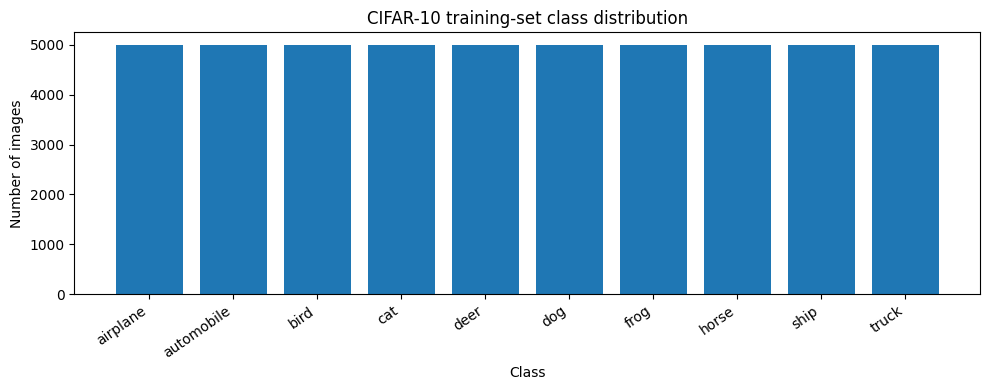

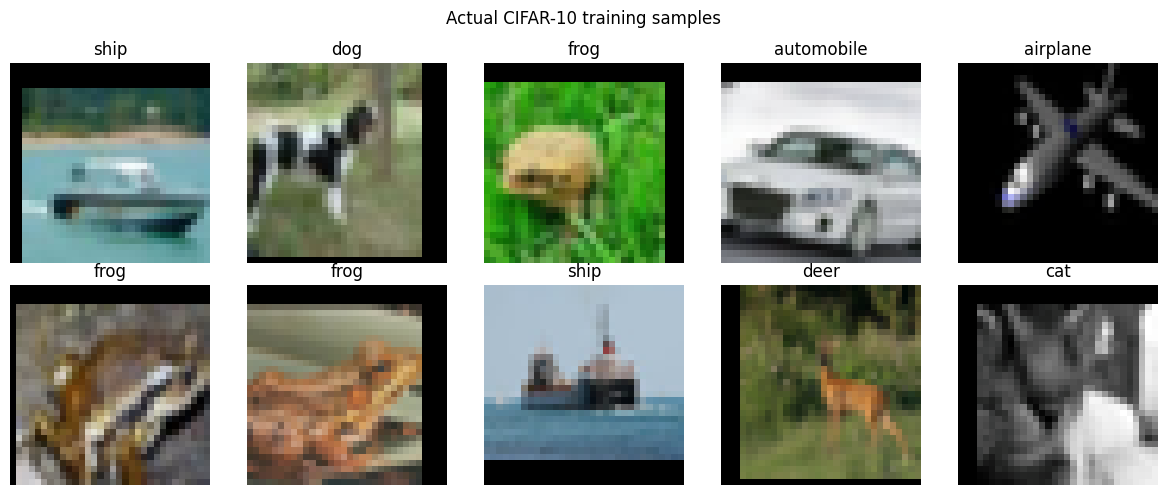

In [ ]:
# CIFAR-10 is balanced: this plot is computed from the actual downloaded labels.
labels = np.array(train_dataset.targets)
counts = np.bincount(labels, minlength=10)

plt.figure(figsize=(10, 4))
plt.bar(class_names, counts)
plt.title("CIFAR-10 training-set class distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Display real images from the training dataset (undo normalization for display).
mean = torch.tensor((0.4914, 0.4822, 0.4465)).view(3,1,1)
std = torch.tensor((0.2470, 0.2435, 0.2616)).view(3,1,1)
images, targets = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    img = (images[i].cpu() * std + mean).clamp(0, 1).permute(1,2,0).numpy()
    ax.imshow(img)
    ax.set_title(class_names[targets[i].item()])
    ax.axis("off")
plt.suptitle("Actual CIFAR-10 training samples")
plt.tight_layout()
plt.show()

## 5. Define the model architecture

A compact convolutional neural network is used for 32×32 RGB images. The final layer returns **10 logits**, one for each CIFAR-10 class. During training, `CrossEntropyLoss` applies the appropriate log-softmax internally.

In [ ]:
class CIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                 # 32x32 -> 16x16

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                 # 16x16 -> 8x8

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

model = CIFAR10CNN().to(DEVICE)
print(model)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Architecture sanity check
with torch.no_grad():
    sample_output = model(torch.randn(2, 3, 32, 32, device=DEVICE))
print("Input shape: (2, 3, 32, 32)")
print("Output shape:", tuple(sample_output.shape))
assert sample_output.shape == (2, 10)

CIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=128, out_features=10, bias=True)
)
Total parameters: 94,762


## 6. Train the model and evaluate on the held-out test set

The epoch count is intentionally modest so the notebook is practical in a Colab lab. Accuracy and loss are measured from actual batches. Increase `EPOCHS` if more training time is available.

In [ ]:
EPOCHS = 8
LEARNING_RATE = 1e-3
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def run_epoch(model, loader, training):
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, 100.0 * correct / total

history = {"train_loss": [], "train_accuracy": [],
           "test_loss": [], "test_accuracy": []}

for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(model, train_loader, training=True)
    test_loss, test_acc = run_epoch(model, test_loader, training=False)
    scheduler.step()
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_accuracy"].append(test_acc)
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
          f"train loss {train_loss:.4f} | train acc {train_acc:.2f}% | "
          f"test loss {test_loss:.4f} | test acc {test_acc:.2f}%")

final_test_loss, final_test_accuracy = run_epoch(model, test_loader, training=False)
print(f"\nFinal held-out test accuracy: {final_test_accuracy:.2f}%")
print(f"Final held-out test loss: {final_test_loss:.4f}")

Epoch 01/8 | train loss 1.5265 | train acc 45.07% | test loss 1.5644 | test acc 42.29%
Epoch 02/8 | train loss 1.2378 | train acc 56.00% | test loss 1.2443 | test acc 55.57%
Epoch 03/8 | train loss 1.1186 | train acc 60.27% | test loss 1.1401 | test acc 58.63%
Epoch 04/8 | train loss 1.0449 | train acc 62.91% | test loss 1.0396 | test acc 63.08%
Epoch 05/8 | train loss 0.9864 | train acc 65.29% | test loss 1.0218 | test acc 63.82%
Epoch 06/8 | train loss 0.9423 | train acc 66.82% | test loss 0.9615 | test acc 66.08%
Epoch 07/8 | train loss 0.9126 | train acc 68.20% | test loss 0.9448 | test acc 66.31%
Epoch 08/8 | train loss 0.8951 | train acc 68.76% | test loss 0.9036 | test acc 67.98%

Final held-out test accuracy: 67.98%
Final held-out test loss: 0.9036


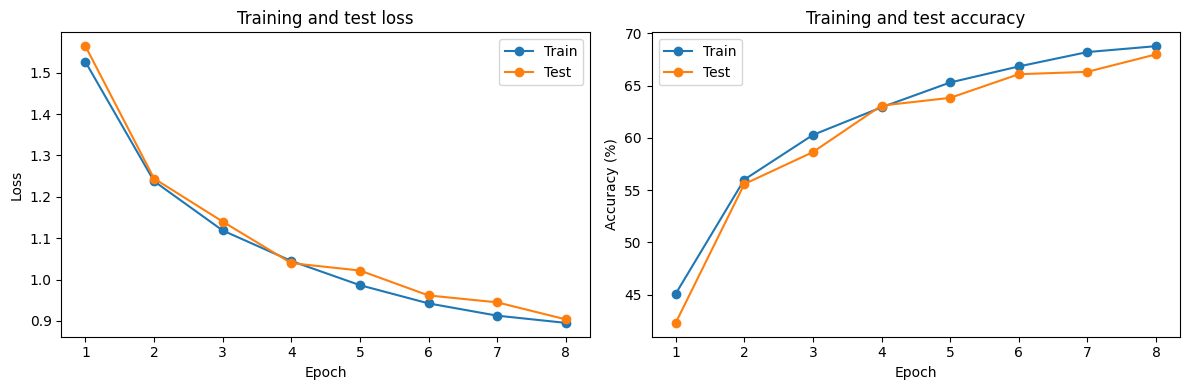

In [ ]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["test_loss"], marker="o", label="Test")
axes[0].set_title("Training and test loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Train")
axes[1].plot(epochs, history["test_accuracy"], marker="o", label="Test")
axes[1].set_title("Training and test accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)"); axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Save the trained checkpoint

A checkpoint stores the learned `state_dict`, architecture settings, class names and training metadata. This is the reusable PyTorch artefact—not just a screenshot of the model.

In [ ]:
ARTIFACT_DIR = Path("/content/model_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = ARTIFACT_DIR / "cifar10_cnn_checkpoint.pth"
checkpoint = {
    "model_name": "CIFAR10CNN",
    "model_config": {"num_classes": 10},
    "state_dict": model.cpu().state_dict(),
    "class_names": class_names,
    "epochs": EPOCHS,
    "test_accuracy_percent": final_test_accuracy,
    "test_loss": final_test_loss,
    "seed": SEED
}
torch.save(checkpoint, checkpoint_path)
model = model.to(DEVICE)
print("Checkpoint saved:", checkpoint_path)
print("Checkpoint size (MB):", round(checkpoint_path.stat().st_size / (1024**2), 3))

# Demonstrate loading the checkpoint into a fresh model instance.
loaded_checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
reloaded_model = CIFAR10CNN(**loaded_checkpoint["model_config"]).to(DEVICE)
reloaded_model.load_state_dict(loaded_checkpoint["state_dict"])
reloaded_model.eval()
print("Checkpoint reload successful.")

Checkpoint saved: /content/model_artifacts/cifar10_cnn_checkpoint.pth
Checkpoint size (MB): 0.371
Checkpoint reload successful.


## 8. Export the trained model to ONNX

ONNX is a framework-independent graph representation. The export uses a dynamic batch dimension so the graph can accept different batch sizes. The model is exported in evaluation mode.

In [ ]:
import onnx
import onnxruntime as ort

onnx_path = ARTIFACT_DIR / "cifar10_cnn.onnx"
reloaded_model.eval()
dummy_input = torch.randn(1, 3, 32, 32, device=DEVICE)

torch.onnx.export(
    reloaded_model,
    dummy_input,
    str(onnx_path),
    input_names=["images"],
    output_names=["logits"],
    dynamic_axes={"images": {0: "batch_size"},
                  "logits": {0: "batch_size"}},
    opset_version=17,
    dynamo=False
)
print("ONNX graph saved:", onnx_path)
print("ONNX file size (MB):", round(onnx_path.stat().st_size / (1024**2), 3))

onnx_model = onnx.load(str(onnx_path))
onnx.checker.check_model(onnx_model)
print("ONNX graph check: PASSED")
print("Graph inputs:", [x.name for x in onnx_model.graph.input])
print("Graph outputs:", [x.name for x in onnx_model.graph.output])
print("Graph nodes:", len(onnx_model.graph.node))

ONNX graph saved: /content/model_artifacts/cifar10_cnn.onnx
ONNX file size (MB): 0.363
ONNX graph check: PASSED
Graph inputs: ['images']
Graph outputs: ['logits']
Graph nodes: 11


/tmp/ipykernel_540/313800311.py:8: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


## 9. Validate ONNX predictions against PyTorch

This is an important correctness check: the same input is passed through PyTorch and ONNX Runtime. We report the maximum absolute difference between logits and check that the predicted classes agree. Small floating-point differences are normal.

In [ ]:
ort_session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
test_images, test_labels = next(iter(test_loader))
input_np = test_images[:16].cpu().numpy().astype(np.float32)

with torch.no_grad():
    pytorch_logits = reloaded_model(torch.from_numpy(input_np).to(DEVICE)).cpu().numpy()

onnx_logits = ort_session.run(["logits"], {"images": input_np})[0]
max_abs_diff = float(np.max(np.abs(pytorch_logits - onnx_logits)))
pytorch_predictions = pytorch_logits.argmax(axis=1)
onnx_predictions = onnx_logits.argmax(axis=1)
prediction_agreement = float(np.mean(pytorch_predictions == onnx_predictions) * 100)

print(f"Maximum absolute logit difference: {max_abs_diff:.8f}")
print(f"Prediction agreement: {prediction_agreement:.2f}%")
assert prediction_agreement == 100.0, "PyTorch and ONNX predicted classes differ; inspect export."
print("PyTorch ↔ ONNX validation: PASSED")

Maximum absolute logit difference: 0.00000238
Prediction agreement: 100.00%
PyTorch ↔ ONNX validation: PASSED


## 10. Evaluate ONNX Runtime on the complete test set

We compute accuracy from all 10,000 test images. This provides a fair comparison with the PyTorch test accuracy.

In [ ]:
def evaluate_onnx(session, loader):
    correct, total, loss_sum = 0, 0, 0.0
    for x, y in loader:
        arr = x.numpy().astype(np.float32)
        logits = session.run(["logits"], {"images": arr})[0]
        pred = logits.argmax(axis=1)
        correct += int((pred == y.numpy()).sum())
        total += len(y)
    return 100.0 * correct / total

onnx_test_accuracy = evaluate_onnx(ort_session, test_loader)
print(f"ONNX Runtime test accuracy: {onnx_test_accuracy:.2f}%")
print(f"PyTorch test accuracy:      {final_test_accuracy:.2f}%")
print(f"Absolute accuracy gap:     {abs(onnx_test_accuracy-final_test_accuracy):.4f} percentage points")

ONNX Runtime test accuracy: 67.98%
PyTorch test accuracy:      67.98%
Absolute accuracy gap:     0.0000 percentage points


## 11. TensorRT environment check

TensorRT is NVIDIA-GPU-specific. First check whether the current runtime has CUDA and TensorRT. If TensorRT is missing, use NVIDIA's installation guidance and choose a package compatible with the installed CUDA/Python version. Do not blindly install a CUDA 13 wheel into a CUDA 12 runtime.

In [ ]:
try:
    import tensorrt as trt
    TRT_AVAILABLE = torch.cuda.is_available()
    print("TensorRT version:", trt.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if not TRT_AVAILABLE:
        print("TensorRT Python package is present, but no CUDA GPU is available.")
except Exception as e:
    trt = None
    TRT_AVAILABLE = False
    print("TensorRT is not ready in this runtime.")
    print("Reason:", repr(e))
    print("A compatible NVIDIA GPU + driver + CUDA + TensorRT installation is required.")
    print("Official installation guide: https://docs.nvidia.com/deeplearning/tensorrt/latest/installing-tensorrt/installing.html")

TensorRT is not ready in this runtime.
Reason: ModuleNotFoundError("No module named 'tensorrt'")
A compatible NVIDIA GPU + driver + CUDA + TensorRT installation is required.
Official installation guide: https://docs.nvidia.com/deeplearning/tensorrt/latest/installing-tensorrt/installing.html


## 12. Build a TensorRT engine from the ONNX graph

This cell runs only when TensorRT and a CUDA GPU are available. It parses the ONNX graph, builds a serialized engine, and saves the hardware-specific `.engine` artefact. Engine files are generally tied to the TensorRT version and target GPU/software environment; do not assume an engine built on one machine will run unchanged on another.

In [ ]:
engine_path = ARTIFACT_DIR / "cifar10_cnn_fp16.engine"

if TRT_AVAILABLE:
    logger = trt.Logger(trt.Logger.WARNING)
    builder = trt.Builder(logger)
    network = builder.create_network(1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH))
    parser = trt.OnnxParser(network, logger)

    with open(onnx_path, "rb") as f:
        parsed = parser.parse(f.read())

    if not parsed:
        for i in range(parser.num_errors):
            print(parser.get_error(i))
        raise RuntimeError("TensorRT could not parse the ONNX model.")

    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)

    # Enable FP16 only if the GPU reports support; otherwise build FP32.
    use_fp16 = builder.platform_has_fast_fp16
    if use_fp16:
        config.set_flag(trt.BuilderFlag.FP16)

    # ONNX graph has a dynamic batch dimension. Define an optimization profile.
    profile = builder.create_optimization_profile()
    profile.set_shape("images", (1, 3, 32, 32),
                      (32, 3, 32, 32), (128, 3, 32, 32))
    config.add_optimization_profile(profile)

    serialized_engine = builder.build_serialized_network(network, config)
    if serialized_engine is None:
        raise RuntimeError("TensorRT engine build failed.")

    with open(engine_path, "wb") as f:
        f.write(serialized_engine)

    print("TensorRT engine saved:", engine_path)
    print("Precision:", "FP16" if use_fp16 else "FP32")
    print("Engine size (MB):", round(engine_path.stat().st_size / (1024**2), 3))
else:
    print("SKIPPED: TensorRT engine cannot be built in the current runtime.")
    print("Complete this stage in a compatible NVIDIA TensorRT environment.")

SKIPPED: TensorRT engine cannot be built in the current runtime.
Complete this stage in a compatible NVIDIA TensorRT environment.


## 13. TensorRT engine load check and inference (when available)

The following uses PyTorch CUDA tensors as device buffers and TensorRT's tensor-address API. It checks that the engine can deserialize and execute, then compares its predictions with PyTorch. If your TensorRT version exposes a different API, use the installed-version documentation rather than treating a skipped cell as a successful engine run.

In [ ]:
if TRT_AVAILABLE and engine_path.exists():
    runtime = trt.Runtime(trt.Logger(trt.Logger.WARNING))
    with open(engine_path, "rb") as f:
        engine = runtime.deserialize_cuda_engine(f.read())
    if engine is None:
        raise RuntimeError("Could not deserialize TensorRT engine.")

    context = engine.create_execution_context()
    input_name, output_name = "images", "logits"
    batch = torch.from_numpy(input_np).to(device="cuda", dtype=torch.float32).contiguous()
    context.set_input_shape(input_name, tuple(batch.shape))

    output_shape = tuple(context.get_tensor_shape(output_name))
    trt_output = torch.empty(output_shape, device="cuda", dtype=torch.float32)
    context.set_tensor_address(input_name, int(batch.data_ptr()))
    context.set_tensor_address(output_name, int(trt_output.data_ptr()))

    ok = context.execute_async_v3(torch.cuda.current_stream().cuda_stream)
    torch.cuda.synchronize()
    if not ok:
        raise RuntimeError("TensorRT execution returned failure.")

    trt_logits = trt_output.cpu().numpy()
    trt_agreement = float(np.mean(trt_logits.argmax(1) == pytorch_predictions) * 100)
    trt_max_diff = float(np.max(np.abs(trt_logits - pytorch_logits)))
    print(f"TensorRT/PyTorch prediction agreement: {trt_agreement:.2f}%")
    print(f"Maximum absolute logit difference: {trt_max_diff:.8f}")
else:
    print("SKIPPED: no TensorRT engine was built in this runtime.")

SKIPPED: no TensorRT engine was built in this runtime.


## 14. Benchmark inference latency

Latency is hardware- and runtime-dependent. The notebook measures the current environment rather than printing assumed speedups. The ONNX Runtime benchmark below uses CPU; PyTorch uses the selected device. Compare only after noting the execution providers and hardware.

In [ ]:
def benchmark_pytorch(model, x, warmup=20, iterations=100):
    model.eval()
    x = x.to(DEVICE)
    with torch.no_grad():
        for _ in range(warmup):
            _ = model(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        for _ in range(iterations):
            _ = model(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
    return (time.perf_counter() - start) * 1000 / iterations

def benchmark_onnx(session, x_np, warmup=20, iterations=100):
    for _ in range(warmup):
        session.run(["logits"], {"images": x_np})
    start = time.perf_counter()
    for _ in range(iterations):
        session.run(["logits"], {"images": x_np})
    return (time.perf_counter() - start) * 1000 / iterations

benchmark_x = test_images[:32]
benchmark_np = benchmark_x.numpy().astype(np.float32)
pytorch_ms = benchmark_pytorch(reloaded_model, benchmark_x)
onnx_ms = benchmark_onnx(ort_session, benchmark_np)

benchmark_results = pd.DataFrame([
    {"Runtime": f"PyTorch ({DEVICE})", "Batch size": 32, "Mean latency (ms)": pytorch_ms},
    {"Runtime": "ONNX Runtime (CPU)", "Batch size": 32, "Mean latency (ms)": onnx_ms}
])
display(benchmark_results)

if TRT_AVAILABLE and engine_path.exists():
    print("TensorRT engine was built and executed in Section 13.")
    print("For a rigorous TensorRT latency benchmark, repeat execution with warm-up and CUDA-event timing on this same GPU.")

## 15. Artefact inventory and download

The output folder contains the architecture's trained checkpoint and ONNX graph. The TensorRT engine appears only if Section 12 successfully built it. A ZIP is created so the artefacts can be downloaded together.

In [ ]:
import zipfile

inventory = []
for p in sorted(ARTIFACT_DIR.glob("*")):
    if p.is_file():
        inventory.append({"Artefact": p.name, "Size (KB)": round(p.stat().st_size / 1024, 2)})
display(pd.DataFrame(inventory))

zip_path = Path("/content/model_lifecycle_artifacts.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in ARTIFACT_DIR.glob("*"):
        if p.is_file():
            zf.write(p, arcname=p.name)

print("Created:", zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("Outside Google Colab: download the ZIP from the file browser:", zip_path)

## 16. Final result summary

This summary is populated from the run's measured values. Do not write down expected or guessed accuracy values before executing the notebook.

In [ ]:
summary = {
    "Dataset": "CIFAR-10",
    "Training samples": len(train_dataset),
    "Test samples": len(test_dataset),
    "Classes": len(class_names),
    "Architecture": "CIFAR10CNN",
    "Trainable parameters": trainable_params,
    "PyTorch test accuracy (%)": round(final_test_accuracy, 2),
    "ONNX Runtime test accuracy (%)": round(onnx_test_accuracy, 2),
    "ONNX validation max absolute difference": round(max_abs_diff, 8),
    "PyTorch/ONNX prediction agreement (%)": round(prediction_agreement, 2),
    "TensorRT available": bool(TRT_AVAILABLE),
    "TensorRT engine built": bool(engine_path.exists())
}
print(json.dumps(summary, indent=2))
with open(ARTIFACT_DIR / "run_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

## What to explain in your lab viva

- **Architecture:** the CNN layer design that defines how input images are processed.
- **Checkpoint (`.pth`):** the trained parameter values and metadata saved from PyTorch.
- **ONNX (`.onnx`):** a portable computation graph exported from the trained model.
- **TensorRT engine (`.engine`):** a hardware-optimized executable plan compiled from ONNX for a compatible NVIDIA GPU.
- **Validation:** compare predictions/logits between frameworks to verify that conversion preserves model behaviour.
- **Benchmarking:** measure latency on the actual runtime and hardware; do not assume TensorRT is faster for every model or batch size.

**Important:** TensorRT engines are deployment artefacts, not interchangeable model weights. Keep the `.pth` checkpoint and `.onnx` graph as portable source artefacts alongside the engine.

### Official references
- [CIFAR-10 dataset description](https://www.tensorflow.org/datasets/catalog/cifar10)
- [Torchvision CIFAR-10 dataset loader](https://docs.pytorch.org/vision/master/generated/torchvision.datasets.CIFAR10.html)
- [PyTorch ONNX export documentation](https://docs.pytorch.org/docs/stable/onnx.html)
- [NVIDIA TensorRT installation guide](https://docs.nvidia.com/deeplearning/tensorrt/latest/installing-tensorrt/installing.html)
- [NVIDIA TensorRT Python API](https://docs.nvidia.com/deeplearning/tensorrt/latest/inference-library/python-api-docs.html)